# 01 — Linking Sewage Works to Local Authorities

**Machine Learning vs Regression for COVID-19 Case Prediction via Wastewater-Based Epidemiology**
Sebastian Munteanu · Department of Mathematical Sciences, University of Bath

---

## The problem this notebook solves

The wastewater data is measured at **sewage treatment works (STWs)**. Each works serves a *catchment* — the area whose sewage flows to it. The COVID-19 case data is reported by **lower tier local authority (LTLA)**.

These two maps of England don't line up. One catchment can cover parts of several local authorities, and one local authority can be served by several works. So before the two datasets can be joined, we need something that says how they overlap.

That is what this notebook builds: a **bridge** table giving, for every works–authority pair, the number of people living in both. That figure becomes the weight used later to decide how much of a works' reading belongs to each authority.

Formally, the shared population between works $s$ and authority $\ell$ is

$$
\text{shared\_population}(s,\ell) \;=\; \sum_{i \in \mathcal{L}} P_i \cdot \frac{A_{i,c(s)}}{\sum_{c'} A_{i,c'}} \cdot \mathbb{1}\{\text{LTLA}(i)=\ell\}
$$

where $\mathcal{L}$ is the set of LSOAs, $P_i$ is the mid-2019 population of LSOA $i$, $A_{i,c}$ is the area where LSOA $i$ overlaps catchment $c$, and $c(s)$ is the catchment of works $s$.

LSOAs (Lower Layer Super Output Areas, roughly 1,500 people each) are the common building block. Both geographies can be expressed in terms of them, so they are what lets the two be connected:

```
STW code            (EMHP wastewater data)
  -> catchment id   (waterbase_catchment_lookup.csv, Hoffmann et al. 2023)
  -> LSOA + overlap (lsoa_catchment_lookup.csv,      Hoffmann et al. 2023)
  -> LSOA population (ONS SAPE mid-2019)
  -> LTLA (LAD 2021) (ONS LSOA11 -> WD21 -> LAD21 lookup)
```

## Why the boundary year matters

Local authority boundaries changed between 2011 and 2021. Councils in Dorset, Suffolk, Northamptonshire, Buckinghamshire, Northumberland and Gateshead were merged or renamed, so the two vintages use different area codes for what is often the same place.

The case data uses **2021** codes. If the bridge were built on 2011 codes instead, 20 authorities on one side and 18 on the other would have no counterpart, and a join would drop them **without any error message** — an inner join loses them, a left join fills them with `NaN`. Worse, the loss would be concentrated in a few counties rather than scattered at random.

This notebook therefore resolves LSOAs straight to 2021 authorities, and §4 checks explicitly that both sides reconcile.

## Terms and abbreviations

This project sits between three fields — public health, geography and statistics — and each brings its own vocabulary. Everything used across the four notebooks is defined here.

### Places

| Term | Meaning |
|---|---|
| **STW** | Sewage treatment works. A plant that treats the sewage from a surrounding area. England has thousands; 269 of them were sampled for COVID-19 during this study period. |
| **Catchment** | The area whose sewage drains to a particular works. Determined by the pipe network, not by any administrative boundary. |
| **LTLA** | Lower Tier Local Authority. The council level at which COVID-19 cases were reported — districts, boroughs and unitary authorities. England has around 300. |
| **LAD** | Local Authority District. The same thing as an LTLA in this context. `LAD21CD` means the 2021 version of the code, `LAD11CD` the 2011 version. |
| **LSOA** | Lower Layer Super Output Area. A small statistical zone of roughly 1,500 people. England has about 33,000. These are the building blocks that let sewage catchments and council boundaries be compared. |
| **`E06…`, `E07…`, `E08…`, `E09…`** | ONS area codes. E06 are unitary authorities, E07 districts, E08 metropolitan boroughs, E09 London boroughs. Codes beginning `S`, `W` or `N` are Scotland, Wales and Northern Ireland, and are excluded throughout. |

### Measurements

| Term | Meaning |
|---|---|
| **SARS-CoV-2 RNA** | Genetic material from the virus. Infected people shed it in their faeces, so it ends up in sewage whether or not they ever take a test. |
| **gc/L** | Gene copies per litre. The unit of concentration in the wastewater data. |
| **`tLOD`** | "Below the limit of detection". A sample was taken and tested, but the concentration was too low to measure — here, under 160 gc/L. Different from no sample being taken at all. |
| **Specimen date** | The day a person's COVID-19 test sample was taken, as opposed to the day the result was published. Used throughout, because it is closer to when the infection actually was. |
| **7-day rolling sum** | Cases over the seven days ending on a given date. Used because raw daily counts dip at weekends for reasons to do with testing habits, not infection. |

### Organisations and datasets

| Name | What it provided |
|---|---|
| **EMHP** | Environmental Monitoring for Health Protection, the UK programme that sampled sewage for SARS-CoV-2. Source of the wastewater data. |
| **UKHSA** | UK Health Security Agency. Ran the COVID-19 dashboard, source of the case counts and vaccination figures. |
| **ONS** | Office for National Statistics. Source of the population estimates, area measurements and geographic lookups. |
| **Hoffmann et al. (2023)** | A published dataset mapping sewage catchments in Great Britain onto LSOAs. Without it there would be no way to connect the two geographies. |
| **IMD** | Index of Multiple Deprivation. The government's official measure of how deprived an area is, combining income, employment, health, education, crime, housing and environment. Higher score means more deprived. |

### The study period

**1 June to 20 September 2021**, 112 days. This window covers the Delta variant wave and the removal of the remaining legal restrictions in England on 19 July 2021, so it contains both a rise and a fall in cases.

## Data sources

| File | Source | What it contains |
|---|---|---|
| `lsoa_catchment_lookup.csv` | Hoffmann et al. (2023) | For each sewage catchment, which LSOAs it overlaps and how much area they share |
| `waterbase_catchment_lookup.csv` | Hoffmann et al. (2023) | Links each catchment to the code of the works that serves it |
| `LSOA11_WD21_LAD21_EW_LU_V2.xlsx` | ONS | Which 2021 local authority each LSOA belongs to |
| `Output_Area_to_..._(December_2011)_Lookup...csv` | ONS | The 2011 version of the same thing, used to build a crosswalk between the two vintages |
| `SAPE22DT2-mid-2019-lsoa-syoa-estimates-unformatted.xlsx` | ONS | Population of each LSOA in mid-2019 |
| `Final_EMHP_concentration_October_2021_data.ods` | EMHP | The wastewater readings, used here only to check the bridge |
| `ltla_newCasesBySpecimenDate.csv` | UKHSA | Daily case counts, used here only to check that area codes match |

## 1. Setup and data loading

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

pd.set_option('display.width', 120)

# ---------------------------------------------------------------------------
# Paths. Nothing here needs editing: the project root is found automatically,
# whether the notebook is run from the notebooks/ folder or from the root.
# ---------------------------------------------------------------------------
PROJECT = Path.cwd()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
DATA = PROJECT / 'data'          # all input files live here
OUT  = PROJECT / 'output'        # everything the notebooks produce goes here
OUT.mkdir(exist_ok=True)
assert DATA.exists(), f'Could not find a data folder at {DATA} - run this notebook from inside the project folder'

FILES = {
    'cat_lsoa' : 'lsoa_catchment_lookup.csv',
    'cat_stw'  : 'waterbase_catchment_lookup.csv',
    'lsoa_lad' : 'LSOA11_WD21_LAD21_EW_LU_V2.xlsx',
    'lad_old'  : 'Output_Area_to_Lower_layer_Super_Output_Area_to_Middle_layer_'
                 'Super_Output_Area_to_Local_Authority_District_(December_2011)_'
                 'Lookup_in_England_and_Wales.csv',
    'pop'      : 'SAPE22DT2-mid-2019-lsoa-syoa-estimates-unformatted.xlsx',
    'emhp'     : 'Final_EMHP_concentration_October_2021_data.ods',
    'cases'    : 'ltla_newCasesBySpecimenDate.csv',
}

missing = [f for f in FILES.values() if not (DATA / f).exists()]
assert not missing, f'Missing input files in {DATA}:\n  ' + '\n  '.join(missing)
print(f'All {len(FILES)} input files found in {DATA}')

STUDY_START, STUDY_END = '2021-06-01', '2021-09-20'

All 7 input files found in /home/claude/project/data


### 1.1 Hoffmann et al. catchment lookups

Two files from the Hoffmann et al. (2023) *Wastewater Catchment Areas in Great Britain* release:

- **`lsoa_catchment_lookup.csv`** — for each catchment, the LSOAs it overlaps and the area of overlap (m²).
- **`waterbase_catchment_lookup.csv`** — links each catchment `identifier` to a treatment-works code (`uwwCode`), which matches the EMHP `Site code`.

In [2]:
cat_lsoa = pd.read_csv(DATA / FILES['cat_lsoa'])
cat_stw  = pd.read_csv(DATA / FILES['cat_stw'])

print('catchment -> LSOA overlaps :', cat_lsoa.shape, list(cat_lsoa.columns))
print('catchment -> STW code      :', cat_stw.shape,  list(cat_stw.columns))
display(cat_lsoa.head(3))
display(cat_stw.head(3))

catchment -> LSOA overlaps : (45271, 3) ['identifier', 'LSOA11CD', 'intersection_area']
catchment -> STW code      : (1784, 5) ['identifier', 'name', 'uwwCode', 'uwwName', 'distance']


,identifier,LSOA11CD,intersection_area
0,6e237d7d4f,E01021768,177231.272895
1,6e237d7d4f,E01021769,160934.444886
2,6e237d7d4f,E01021796,157677.752105


,identifier,name,uwwCode,uwwName,distance
0,db0c16f480,Acle-Damgate Lane,UKENAN_AW_TP000001,ACLE STW,0.0
1,9993422f66,Alconbury,UKENAN_AW_TP000002,ALCONBURY STW,0.0
2,a96313b815,Alford,UKENAN_AW_TP000003,ALFORD STW,0.0


### 1.2 ONS LSOA (2011) → LAD (2021) lookup

The ONS *LSOA (2011) to Electoral Ward (2021) to LAD (2021) Best Fit Lookup in EW (V2)*. We keep only the LSOA and LAD columns.

**On "best fit".** The label refers to the *ward* column: 2011 LSOAs do not nest exactly inside 2021 wards. The LSOA→LAD relationship, which is the part used here, is exact — the 2019–2021 reorganisations merged **whole districts**, so no LSOA is split across two 2021 LADs. The assertion below tests this rather than assuming it.

In [3]:
lsoa_lad = (pd.read_excel(DATA / FILES['lsoa_lad'], sheet_name='LSOA11_WD21_LAD21_EW_LU')
              [['LSOA11CD', 'LAD21CD', 'LAD21NM']]
              .drop_duplicates())

assert lsoa_lad['LSOA11CD'].is_unique, 'an LSOA maps to more than one 2021 LAD'

print('LSOA -> LAD21 pairs :', len(lsoa_lad), '| unique LSOAs :', lsoa_lad['LSOA11CD'].nunique(),
      '| unique LADs :', lsoa_lad['LAD21CD'].nunique())
display(lsoa_lad.head(3))

LSOA -> LAD21 pairs : 34753 | unique LSOAs : 34753 | unique LADs : 331


,LSOA11CD,LAD21CD,LAD21NM
0,E01011965,E06000001,Hartlepool
1,E01011951,E06000001,Hartlepool
2,E01011964,E06000001,Hartlepool


### 1.3 ONS mid-2019 LSOA population estimates

ONS Small Area Population Estimates (`SAPE22DT2`, mid-2019), sheet *Mid-2019 Persons*, column *All Ages*; the data starts on row 5, so four header rows are skipped.

Mid-2019 is chosen because it is the same vintage the EMHP programme used for its own catchment population figures, which is what makes the cross-check in §3 a fair test rather than a comparison of two different denominators.

In [4]:
pop = (pd.read_excel(DATA / FILES['pop'], sheet_name='Mid-2019 Persons', skiprows=4)
         [['LSOA Code', 'All Ages']]
         .rename(columns={'LSOA Code': 'LSOA11CD', 'All Ages': 'population'})
         .dropna(subset=['LSOA11CD']))

print('LSOA population rows :', len(pop), '| total population :', f"{pop['population'].sum():,.0f}")
display(pop.head(3))

/usr/local/lib/python3.11/dist-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


LSOA population rows : 34753 | total population : 59,439,840


,LSOA11CD,population
0,E01011949,1954
1,E01011950,1257
2,E01011951,1209


### 1.4 A LAD 2011 → LAD 2021 crosswalk

The case data (§4) turns out to use **2011** codes for two counties, so a crosswalk between the two vintages is needed. Rather than download a further file, it is derived from the two lookups already loaded: both are keyed on 2011 LSOAs, so joining them on `LSOA11CD` and taking the distinct LAD pairs yields the crosswalk directly.

This is self-contained and auditable — the crosswalk is a *consequence* of the ONS geography files rather than a third-party mapping taken on trust.

In [5]:
lad11 = (pd.read_csv(DATA / FILES['lad_old'], low_memory=False)
           [['LSOA11CD', 'LAD11CD', 'LAD11NM']].drop_duplicates())

crosswalk = (lad11.merge(lsoa_lad, on='LSOA11CD')
                  [['LAD11CD', 'LAD11NM', 'LAD21CD', 'LAD21NM']]
                  .drop_duplicates().sort_values('LAD11CD').reset_index(drop=True))

assert (crosswalk.groupby('LAD11CD')['LAD21CD'].nunique() == 1).all(), '2011 LAD split across 2021 LADs'

changed = crosswalk[crosswalk.LAD11CD != crosswalk.LAD21CD]
print(f'{len(crosswalk)} LAD11 codes -> {crosswalk.LAD21CD.nunique()} LAD21 codes '
      f'({len(changed)} codes changed between vintages)')
display(changed)

348 LAD11 codes -> 331 LAD21 codes (31 codes changed between vintages)


,LAD11CD,LAD11NM,LAD21CD,LAD21NM
27,E06000028,Bournemouth,E06000058,"Bournemouth, Christchurch and Poole"
28,E06000029,Poole,E06000058,"Bournemouth, Christchurch and Poole"
47,E06000048,Northumberland,E06000057,Northumberland
56,E07000004,Aylesbury Vale,E06000060,Buckinghamshire
57,E07000005,Chiltern,E06000060,Buckinghamshire
58,E07000006,South Bucks,E06000060,Buckinghamshire
59,E07000007,Wycombe,E06000060,Buckinghamshire
87,E07000048,Christchurch,E06000058,"Bournemouth, Christchurch and Poole"
88,E07000049,East Dorset,E06000059,Dorset
89,E07000050,North Dorset,E06000059,Dorset


### 1.5 Dashboard reporting units

Two LTLAs are not reported separately by the UKHSA dashboard: the City of London is reported with Hackney, and the Isles of Scilly with Cornwall. To make the bridge and the case data directly comparable, the bridge adopts the same convention.

The City of London contributes ~9,700 people to the bridge; the Isles of Scilly contribute none (no mapped catchment). The effect is small, but leaving it unhandled would leave a phantom unmatched LTLA in §4 and obscure any real mismatch.

In [6]:
REPORTING_FOLD = {
    'E09000001': ('E09000012', 'Hackney and City of London'),
    'E06000053': ('E06000052', 'Cornwall and Isles of Scilly'),
}

def fold_code(code):
    return REPORTING_FOLD.get(code, (code,))[0]

## 2. Building the bridge

The lookups are chained with a series of joins, then a population weight is computed for each STW–LSOA piece.

**Weighting choice.** Where an LSOA is split across more than one catchment, that LSOA's population is divided between catchments in proportion to the **area** of overlap. This is a transparent approximation. Hoffmann et al. instead assign each LSOA to a catchment by its population-weighted centroid. Area-weighting will over-attribute population wherever a catchment's overlap with an LSOA falls in the sparsely-populated part of it, which is the likely source of the small positive bias observed in §3.

In [7]:
bridge = (cat_lsoa
    .merge(cat_stw[['identifier', 'uwwCode', 'uwwName']], on='identifier', how='left')  # (a) STW code
    .merge(lsoa_lad,                                      on='LSOA11CD',   how='left')  # (b) 2021 LTLA
    .merge(pop,                                           on='LSOA11CD',   how='left')) # (c) population

print('Bridge rows after joins :', len(bridge))
print('  missing STW code      :', bridge['uwwCode'].isna().sum(),
      '(catchments with no matching treatment works - dropped below)')
print('  missing LAD21         :', bridge['LAD21CD'].isna().sum())
print('  missing population    :', bridge['population'].isna().sum())

Bridge rows after joins : 45319
  missing STW code      : 6547 (catchments with no matching treatment works - dropped below)
  missing LAD21         : 0
  missing population    : 0


In [8]:
# Population weight for each (catchment, LSOA) piece:
# if an LSOA is shared by several catchments, split its population by area share.
bridge['lsoa_area_total'] = bridge.groupby('LSOA11CD')['intersection_area'].transform('sum')
bridge['area_frac']       = bridge['intersection_area'] / bridge['lsoa_area_total']
bridge['pop_contrib']     = bridge['population'] * bridge['area_frac']

# area fractions must sum to 1 within each LSOA
assert np.allclose(bridge.groupby('LSOA11CD')['area_frac'].sum(), 1.0), 'area fractions do not sum to 1'

# apply the dashboard reporting convention
bridge['LAD21NM'] = np.where(bridge.LAD21CD.isin(REPORTING_FOLD),
                             bridge.LAD21CD.map(lambda c: REPORTING_FOLD.get(c, (None, None))[1]),
                             bridge.LAD21NM)
bridge['LAD21CD'] = bridge.LAD21CD.map(fold_code)

### 2.1 Aggregate to STW × LTLA

Summing the population contributions over LSOAs gives the shared population between every STW and every LTLA it serves — the final bridge table.

In [9]:
stw_ltla = (bridge
    .dropna(subset=['uwwCode', 'LAD21CD'])
    .groupby(['uwwCode', 'uwwName', 'LAD21CD', 'LAD21NM'], as_index=False)['pop_contrib']
    .sum()
    .rename(columns={'pop_contrib': 'shared_population'}))

stw_ltla = (stw_ltla[stw_ltla.shared_population > 0]
            .sort_values(['uwwCode', 'shared_population'], ascending=[True, False])
            .reset_index(drop=True))

print('STW-LTLA pairs   :', len(stw_ltla))
print('unique STWs      :', stw_ltla['uwwCode'].nunique())
print('unique LTLAs     :', stw_ltla['LAD21CD'].nunique())
print('total population :', f"{stw_ltla['shared_population'].sum():,.0f}")
display(stw_ltla.head(5))

STW-LTLA pairs   : 2480
unique STWs      : 1570
unique LTLAs     : 328
total population : 56,366,570


,uwwCode,uwwName,LAD21CD,LAD21NM,shared_population
0,UKENAN_AW_TP000001,ACLE STW,E07000144,Broadland,3996.352409
1,UKENAN_AW_TP000001,ACLE STW,E07000145,Great Yarmouth,7.294640
2,UKENAN_AW_TP000002,ALCONBURY STW,E07000011,Huntingdonshire,3438.472835
3,UKENAN_AW_TP000003,ALFORD STW,E07000137,East Lindsey,4429.860047
4,UKENAN_AW_TP000004,ANWICK STW,E07000139,North Kesteven,5977.464654


### 2.2 Sanity check — a large multi-LTLA STW

Mogden STW serves much of west London, so it should split across many LTLAs with the bulk in the west-London boroughs. An eyeball check that the weighting behaves sensibly.

In [10]:
mogden = stw_ltla[stw_ltla['uwwName'].str.contains('Mogden', case=False, na=False)]
print(f'Mogden serves {len(mogden)} LTLAs, total population {mogden.shared_population.sum():,.0f}')
display(mogden.sort_values('shared_population', ascending=False).head(10))

Mogden serves 19 LTLAs, total population 1,782,705


,uwwCode,uwwName,LAD21CD,LAD21NM,shared_population
2189,UKENTH_TWU_TP000113,LONDON (Mogden STW),E09000017,Hillingdon,306830.053881
2190,UKENTH_TWU_TP000113,LONDON (Mogden STW),E09000009,Ealing,275715.822120
2191,UKENTH_TWU_TP000113,LONDON (Mogden STW),E09000018,Hounslow,270824.357460
2192,UKENTH_TWU_TP000113,LONDON (Mogden STW),E09000015,Harrow,251153.004735
2193,UKENTH_TWU_TP000113,LONDON (Mogden STW),E09000003,Barnet,198224.861030
2194,UKENTH_TWU_TP000113,LONDON (Mogden STW),E09000027,Richmond upon Thames,197019.900949
2195,UKENTH_TWU_TP000113,LONDON (Mogden STW),E09000005,Brent,165079.315241
2196,UKENTH_TWU_TP000113,LONDON (Mogden STW),E07000213,Spelthorne,99844.000000
2197,UKENTH_TWU_TP000113,LONDON (Mogden STW),E06000060,Buckinghamshire,5225.649235
2198,UKENTH_TWU_TP000113,LONDON (Mogden STW),E06000040,Windsor and Maidenhead,4471.370540


## 3. Validating the bridge against EMHP

A bridge that *runs* is not necessarily *correct*. Two checks against the real wastewater data:

1. **Coverage** — do all the STWs actually sampled by EMHP appear in the bridge?
2. **Population cross-check** — does the population reconstructed for each STW match the catchment population EMHP reports for it? EMHP computed theirs independently, so close agreement is strong evidence the linkage is right.

In [11]:
xl    = pd.ExcelFile(DATA / FILES['emhp'], engine='odf')
daily = xl.parse('Daily_concentrations', skiprows=2)
daily.columns = daily.iloc[0]                # row 0 holds the real headers
daily = daily[1:].reset_index(drop=True)

emhp_stws = daily[['Region', 'Site code', 'Site name', 'Catchment population']].copy()
emhp_stws['Catchment population'] = pd.to_numeric(emhp_stws['Catchment population'], errors='coerce')

print('EMHP sampled STWs :', emhp_stws['Site code'].nunique())
display(emhp_stws.head(3))

EMHP sampled STWs : 269


,Region,Site code,Site name,Catchment population
0,East Midlands,UKENAN_AW_TP000004,Anwick,5866
1,East Midlands,UKENAN_AW_TP000023,Boston,38150
2,East Midlands,UKENAN_AW_TP000026,Bourne,21752


### 3.1 Validation 1 — coverage of sampled STWs

In [12]:
emhp_codes   = set(emhp_stws['Site code'].dropna())
bridge_codes = set(stw_ltla['uwwCode'].dropna())
unmatched    = emhp_codes - bridge_codes

print(f'EMHP sampled STWs : {len(emhp_codes)}')
print(f'Matched to bridge : {len(emhp_codes & bridge_codes)} '
      f'({100*len(emhp_codes & bridge_codes)/len(emhp_codes):.1f}%)')
print(f'Unmatched         : {len(unmatched)}')

assert not unmatched, f'EMHP STWs absent from the bridge: {sorted(unmatched)}'

EMHP sampled STWs : 269
Matched to bridge : 269 (100.0%)
Unmatched         : 0


### 3.2 Validation 2 — population cross-check

In [13]:
bridged_pop = (stw_ltla.groupby('uwwCode', as_index=False)['shared_population']
                       .sum().rename(columns={'shared_population': 'bridged_pop'}))

comp = emhp_stws.merge(bridged_pop, left_on='Site code', right_on='uwwCode', how='left')
comp['ratio']   = comp['bridged_pop'] / comp['Catchment population']
comp['abs_dev'] = (comp['ratio'] - 1).abs()

print('EMHP total catchment pop :', f"{comp['Catchment population'].sum():>14,.0f}")
print('Bridged total pop        :', f"{comp['bridged_pop'].sum():>14,.0f}")
print('Overall ratio            :', f"{comp['bridged_pop'].sum()/comp['Catchment population'].sum():.4f}")
print()
print('Per-STW ratio (bridged / EMHP):')
print(comp['ratio'].describe().to_string())

within = comp['ratio'].between(0.7, 1.3).sum()
print(f"\nSTWs within +/-30% of EMHP figure : {within}/{len(comp)} ({100*within/len(comp):.1f}%)")

EMHP total catchment pop :     36,732,384
Bridged total pop        :     36,834,290
Overall ratio            : 1.0028

Per-STW ratio (bridged / EMHP):
count    269.000000
mean       1.040312
std        0.093329
min        0.002150
25%        1.010329
50%        1.029228
75%        1.057840
max        1.358462

STWs within +/-30% of EMHP figure : 262/269 (97.4%)


The median ratio sits a little above 1. That upward bias is what the area-weighting choice in §2 would predict, so it is worth stating rather than leaving as unexplained noise. Splitting an LSOA's population by area over-attributes wherever the overlapping portion is less densely populated than the LSOA average.

### 3.3 Inspect the outliers

The STWs whose reconstructed population deviates most from the EMHP figure. These are likely catchment-boundary mismatches in the underlying Hoffmann data and need individual investigation (keep / correct / exclude) — genuine data-quality work, not something to automate away.

In [14]:
outliers = comp.sort_values('abs_dev', ascending=False).head(10)
display(outliers[['Site name', 'Region', 'Catchment population', 'bridged_pop', 'ratio']]
        .style.format({'Catchment population': '{:,.0f}', 'bridged_pop': '{:,.0f}', 'ratio': '{:.3f}'}))

,Site name,Region,Catchment population,bridged_pop,ratio
71,Radlett,East of England,"596,582","1,282",0.002
193,Plympton,South West,"106,232","59,762",0.563
57,Reepham,East of England,"4,497","6,109",1.358
53,Needham Market,East of England,"6,988","9,480",1.357
165,Didcot,South East,"31,783","42,197",1.328
61,Stalham,East of England,"7,160","9,309",1.300
34,Chalton,East of England,"112,126","145,775",1.300
156,Alton,South East,"24,715","32,119",1.300
207,Shaftesbury,South West,"9,139","11,232",1.229
210,Blandford Forum,South West,"17,403","21,075",1.211


### 3.4 Visualise the agreement

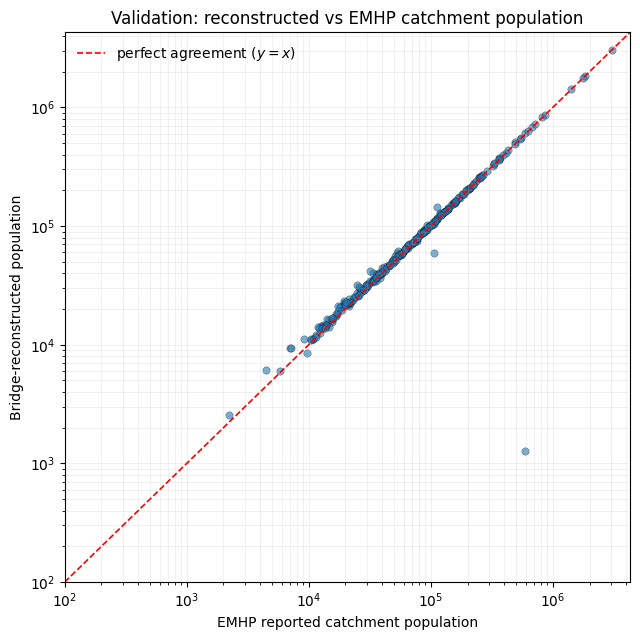

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(comp['Catchment population'], comp['bridged_pop'],
           alpha=0.6, s=28, edgecolor='k', linewidth=0.3)

lims = [1e2, comp[['Catchment population', 'bridged_pop']].max().max() * 1.4]
ax.plot(lims, lims, 'r--', lw=1.2, label='perfect agreement ($y = x$)')
ax.set(xscale='log', yscale='log', xlim=lims, ylim=lims,
       xlabel='EMHP reported catchment population',
       ylabel='Bridge-reconstructed population',
       title='Validation: reconstructed vs EMHP catchment population')
ax.legend(frameon=False)
ax.grid(alpha=0.25, which='both', lw=0.5)
fig.tight_layout()
plt.show()

## 4. Reconciling with the case data

This section is the reason the notebook was revised. It checks that every LTLA in the bridge has a counterpart in the case data and vice versa — the check that would have caught the 2011/2021 vintage mismatch.

Two complications in the UKHSA archive, both discovered here rather than assumed:

1. **Mixed vintages.** The file uses 2021 codes throughout *except* for Buckinghamshire and Northamptonshire, which are still reported under their pre-reorganisation district codes right through the study period. Those cases (≈52,000 in the window) would be lost entirely by a naive join on 2021 codes.
2. **A stray October 2020 block.** The codes `E06000060`, `E06000061`, `E06000062` and `E09000001` each appear with exactly 31 rows, all in October 2020, and nowhere else. This is outside the study window so it does not affect this analysis, but it *would* double-count if the crosswalk were applied to the full series without care — worth a guard if the study period is ever extended.

In [16]:
cases = pd.read_csv(DATA / FILES['cases'], usecols=['date', 'area_code', 'area_name', 'value'])
cases = cases[cases.area_code.str.startswith('E')].copy()

# NB: the three ltla_newCases* files do NOT share a date format. This one is DD/MM/YYYY.
# Always parse with an explicit format rather than letting pandas infer.
cases['date'] = pd.to_datetime(cases['date'], format='%d/%m/%Y')

window = cases[cases.date.between(STUDY_START, STUDY_END)].copy()
print(f'study window {STUDY_START} to {STUDY_END}')
print(f'  rows {len(window):,} | LTLA codes {window.area_code.nunique()} '
      f'| dates {window.date.nunique()} | cases {window.value.sum():,.0f}')

study window 2021-06-01 to 2021-09-20
  rows 35,280 | LTLA codes 315 | dates 112 | cases 2,543,938


In [17]:
# Harmonise the case data onto 2021 codes, then onto dashboard reporting units.
lad_map = dict(zip(crosswalk.LAD11CD, crosswalk.LAD21CD))

window['LAD21CD'] = window.area_code.map(lad_map).fillna(window.area_code).map(fold_code)
cases_ltla = window.groupby(['LAD21CD', 'date'], as_index=False)['value'].sum()

# harmonisation must move cases between codes, never create or destroy them
assert cases_ltla.value.sum() == window.value.sum(), 'cases lost or duplicated in harmonisation'

print(f'after harmonisation: rows {len(cases_ltla):,} | LTLAs {cases_ltla.LAD21CD.nunique()} '
      f'| cases {cases_ltla.value.sum():,.0f}')

after harmonisation: rows 34,384 | LTLAs 307 | cases 2,543,938


In [18]:
bridge_ltlas = set(stw_ltla[stw_ltla.LAD21CD.str.startswith('E')].LAD21CD)
case_ltlas   = set(cases_ltla.LAD21CD)

print(f'LTLAs in bridge : {len(bridge_ltlas)}')
print(f'LTLAs in cases  : {len(case_ltlas)}')
print(f'in bridge, not in cases : {sorted(bridge_ltlas - case_ltlas)}')
print(f'in cases, not in bridge : {sorted(case_ltlas - bridge_ltlas)}')

assert not (bridge_ltlas - case_ltlas), 'bridge LTLAs with no case data'
assert not (case_ltlas - bridge_ltlas), 'case LTLAs with no bridge entry'
print('\nEvery LTLA reconciles on both sides.')

LTLAs in bridge : 307
LTLAs in cases  : 307
in bridge, not in cases : []
in cases, not in bridge : []

Every LTLA reconciles on both sides.


## 5. Save outputs

In [19]:
stw_ltla.to_csv(OUT / 'stw_ltla_bridge.csv', index=False)
comp.drop(columns=['uwwCode']).to_csv(OUT / 'population_validation.csv', index=False)
crosswalk.to_csv(OUT / 'lad11_to_lad21.csv', index=False)

for f in ['stw_ltla_bridge.csv', 'population_validation.csv', 'lad11_to_lad21.csv']:
    print(f'saved: {f}')

saved: stw_ltla_bridge.csv
saved: population_validation.csv
saved: lad11_to_lad21.csv


## 6. Summary

The bridge links all 269 sampled works to 2021 local authorities. The populations it reconstructs agree with EMHP's own independently calculated figures to within 0.3% overall, and 262 of 269 individual sites agree to within 30%. Every authority reconciles against the case data in both directions.

### Decisions made here

| Decision | Choice | Alternative | Where it shows up |
|---|---|---|---|
| Splitting an LSOA's population between catchments | By area of overlap | Population-weighted centroid (Hoffmann et al.) | Likely source of the ~3% upward bias in §3.2 |
| Boundary year | 2021 | 2011 | Would silently drop 20 authorities (§4) |
| Bucks and Northants case codes | Rolled up to 2021 unitaries | Drop them, or split the bridge back to districts | About 52,000 cases in the study window |
| City of London, Isles of Scilly | Merged into Hackney and Cornwall | Keep separate | Matches how the dashboard itself reports |

### Still open

Radlett (ratio 0.002) and Plympton (0.56) are unexplained. Both need looking at individually and a decision recording: keep, correct, or exclude.

### What comes next

`stw_ltla_bridge.csv` and `lad11_to_lad21.csv` are the inputs to **notebook 02**, which uses them to combine the wastewater readings with the case counts into a single dataset.